Clase IA
Regresion lineal California Housing

Importar librerias

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Cargar dataset

In [3]:
housing = fetch_california_housing(as_frame=True)

df = housing.frame
X = housing.data
y = housing.target

print("Tamaño del dataset:", df.shape)
df.head()

Tamaño del dataset: (20640, 9)


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [4]:
print("Valores nulos por columna:")
print(df.isnull().sum())

df.describe().round(2)

Valores nulos por columna:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00,20640.00
mean,3.87,28.64,5.43,1.10,1425.48,3.07,35.63,-119.57,2.07
std,1.90,12.59,2.47,0.47,1132.46,10.39,2.14,2.00,1.15
min,0.50,1.00,0.85,0.33,3.00,0.69,32.54,-124.35,0.15
25%,2.56,18.00,4.44,1.01,787.00,2.43,33.93,-121.80,1.20
50%,3.53,29.00,5.23,1.05,1166.00,2.82,34.26,-118.49,1.80
75%,4.74,37.00,6.05,1.10,1725.00,3.28,37.71,-118.01,2.65
max,15.00,52.00,141.91,34.07,35682.00,1243.33,41.95,-114.31,5.00


Entrenamiento del modelo

In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

modelo = LinearRegression()
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)


Entrenamiento: (16512, 8)
Prueba: (4128, 8)


In [7]:
print(f"MAE:  {mae:.3f}  (${mae * 100_000:,.0f})")
print(f"RMSE: {rmse:.3f}  (${rmse * 100_000:,.0f})")
print(f"R²:   {r2:.3f}")

MAE:  0.533  ($53,320)
RMSE: 0.746  ($74,558)
R²:   0.576


Contraste entre valores reales y predicho

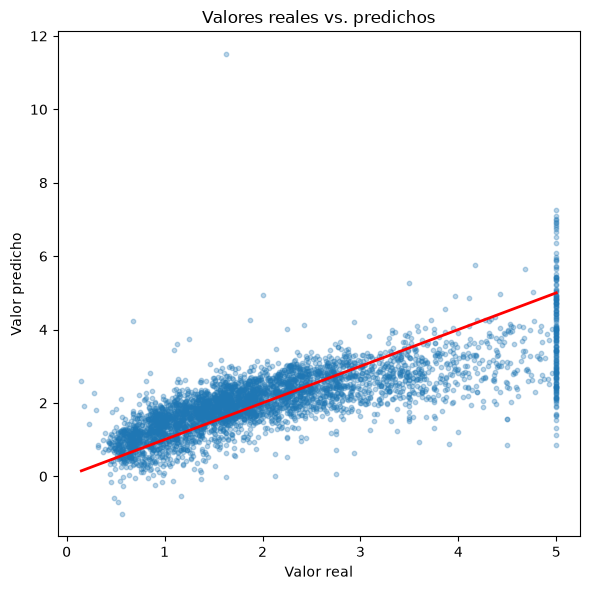

In [8]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.3, s=10)
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], color="red", linewidth=2)
plt.xlabel("Valor real")
plt.ylabel("Valor predicho")
plt.title("Valores reales vs. predichos")
plt.tight_layout()
plt.show()

Predicción de una nueva casa

In [9]:
nueva_casa = pd.DataFrame([{
    "MedInc": 5.0,
    "HouseAge": 20,
    "AveRooms": 6.0,
    "AveBedrms": 1.0,
    "Population": 1500,
    "AveOccup": 3.0,
    "Latitude": 34.0,
    "Longitude": -118.3,
}])

precio = modelo.predict(nueva_casa)[0]
print(f"Precio estimado: {precio:.2f}  (${precio * 100_000:,.0f})")

Precio estimado: 2.48  ($247,888)
